# Lab 07 - Đánh giá mô hình (6 bài tập)

- **Môn học** Học máy ứng dụng
- **Giảng viên biên soạn** ThS. Nguyễn Thái Anh
- **Sinh viên** Huỳnh Hữu Phúc
- **MSSV** 2474802010314

Lời giải cho mục 8 của PDF Lab 7. Chạy với thư mục làm việc là 07.Accuracy_Metrics. Mỗi bài có thể chạy riêng và Bài 4 xuất figures/roc.png.

## Bài 1. Tự viết hàm đánh giá

**Đề bài**

Viết `danh_gia(y_that, y_doan)` chỉ dùng NumPy để tính accuracy, precision, recall và F1. Chạy cho logistic và mô hình lười ở mục 2, đối chiếu với scikit-learn. Giải thích precision của mô hình lười và cách xử lý khi mẫu số bằng 0.

In [1]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def dem_bon_o(y_that, y_doan):
    """Đếm theo thứ tự TN, FP, FN, TP với lớp dương là 1."""
    y_that = np.asarray(y_that)
    y_doan = np.asarray(y_doan)
    tn = np.count_nonzero((y_that == 0) & (y_doan == 0))
    fp = np.count_nonzero((y_that == 0) & (y_doan == 1))
    fn = np.count_nonzero((y_that == 1) & (y_doan == 0))
    tp = np.count_nonzero((y_that == 1) & (y_doan == 1))
    return tn, fp, fn, tp


def danh_gia(y_that, y_doan):
    """Tính bốn thước đo cho nhãn nhị phân 0/1 bằng NumPy."""
    tn, fp, fn, tp = dem_bon_o(y_that, y_doan)
    tong = tn + fp + fn + tp
    so_doan_duong = tp + fp
    so_that_duong = tp + fn
    mau_f1 = 2 * tp + fp + fn
    return {
        "Accuracy": (tp + tn) / tong if tong else 0.0,
        "Precision": tp / so_doan_duong if so_doan_duong else 0.0,
        "Recall": tp / so_that_duong if so_that_duong else 0.0,
        "F1": 2 * tp / mau_f1 if mau_f1 else 0.0,
    }


du_lieu = pd.read_csv("data/sinh_vien_bo_hoc.csv")
dac_trung = du_lieu.drop(columns="bo_hoc")
nhan = du_lieu["bo_hoc"]
X_hoc, X_kiem_tra, y_hoc, y_kiem_tra = train_test_split(
    dac_trung, nhan, test_size=0.25, random_state=17, stratify=nhan
)

cac_mo_hinh = {
    "Hồi quy logistic": make_pipeline(StandardScaler(), LogisticRegression()),
    "Mô hình lười": DummyClassifier(strategy="most_frequent"),
}
for ten, mo_hinh in cac_mo_hinh.items():
    du_doan = mo_hinh.fit(X_hoc, y_hoc).predict(X_kiem_tra)
    tn, fp, fn, tp = dem_bon_o(y_kiem_tra, du_doan)
    bang_nham_lan = np.array([[tn, fp], [fn, tp]])
    np.testing.assert_array_equal(
        bang_nham_lan, confusion_matrix(y_kiem_tra, du_doan, labels=[0, 1])
    )
    tu_tinh = danh_gia(y_kiem_tra, du_doan)
    thu_vien = {
        "Accuracy": accuracy_score(y_kiem_tra, du_doan),
        "Precision": precision_score(y_kiem_tra, du_doan, zero_division=0),
        "Recall": recall_score(y_kiem_tra, du_doan, zero_division=0),
        "F1": f1_score(y_kiem_tra, du_doan, zero_division=0),
    }
    np.testing.assert_allclose(list(tu_tinh.values()), list(thu_vien.values()))

    print(ten)
    print("Ma trận nhầm lẫn (hàng thật, cột đoán, thứ tự lớp 0 rồi 1)")
    print(bang_nham_lan)
    print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
    print(pd.DataFrame({"Tự tính": tu_tinh, "scikit-learn": thu_vien}).to_string(
        float_format=lambda diem: f"{diem:.4f}"
    ))
    if tp + fp == 0:
        print("Precision có mẫu số bằng 0. Giá trị báo cáo theo quy ước là 0.")
    print()

Hồi quy logistic
Ma trận nhầm lẫn (hàng thật, cột đoán, thứ tự lớp 0 rồi 1)
[[267   3]
 [ 13  17]]
TN = 267, FP = 3, FN = 13, TP = 17
           Tự tính  scikit-learn
Accuracy    0.9467        0.9467
Precision   0.8500        0.8500
Recall      0.5667        0.5667
F1          0.6800        0.6800

Mô hình lười
Ma trận nhầm lẫn (hàng thật, cột đoán, thứ tự lớp 0 rồi 1)
[[270   0]
 [ 30   0]]
TN = 270, FP = 0, FN = 30, TP = 0
           Tự tính  scikit-learn
Accuracy    0.9000        0.9000
Precision   0.0000        0.0000
Recall      0.0000        0.0000
F1          0.0000        0.0000
Precision có mẫu số bằng 0. Giá trị báo cáo theo quy ước là 0.



**Giải thích và nhận xét**

Lớp dương là **bỏ học** (nhãn 1). Hàng là nhãn thật và cột là nhãn dự đoán. Vì vậy thứ tự trải ma trận theo hàng là **TN, FP, FN, TP**.

| Ô | Ý nghĩa với trường hợp bỏ học | Logistic | Mô hình lười |
|---|---|---:|---:|
| TN (thật 0, đoán 0) | Bạn vẫn học và mô hình dự đoán học tiếp. | 267 | 270 |
| FP (thật 0, đoán 1) | Bạn vẫn học nhưng mô hình báo có nguy cơ, tức cảnh báo nhầm. | 3 | 0 |
| FN (thật 1, đoán 0) | Bạn bỏ học nhưng mô hình dự đoán học tiếp, tức bỏ sót. | 13 | 30 |
| TP (thật 1, đoán 1) | Bạn bỏ học và mô hình phát hiện đúng. | 17 | 0 |

- **Accuracy** lấy số dự đoán đúng chia cho toàn bộ mẫu. Logistic đạt $(267+17)/300=0.9467$. Mô hình lười đạt $270/300=0.9000$ nhờ dự đoán đúng lớp đông.
- **Precision** chia cho số cảnh báo $TP+FP$. Logistic đạt $17/20=0.8500$. Mô hình lười không phát cảnh báo nào nên precision có dạng $0/0$ và không xác định về mặt toán học. Hàm trả về `0.0` theo quy ước, tương ứng với `zero_division=0` của scikit-learn.
- **Recall** chia cho số ca bỏ học thật $TP+FN$. Logistic đạt $17/30=0.5667$. Mô hình lười có recall $0/30=0$ vì bỏ sót cả 30 bạn.
- **F1** tính theo $2TP/(2TP+FP+FN)$. Logistic được $34/50=0.6800$, mô hình lười được $0/30=0$. Hai cách tính cho cùng kết quả trên cả hai mô hình.

## Bài 2. Chữ số viết tay

**Đề bài**

Chạy lại SVM RBF nhận dạng chữ số của Lab 6, in `classification_report` cho cả 10 lớp. Xác định chữ số có recall và precision thấp nhất. Giải thích vì sao `macro avg` và `weighted avg` gần bằng nhau.

In [2]:
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

anh, chu_so = load_digits(return_X_y=True)
anh_hoc, anh_kiem_tra, nhan_hoc, nhan_kiem_tra = train_test_split(
    anh, chu_so, test_size=0.25, random_state=17, stratify=chu_so
)
svm = SVC(kernel="rbf").fit(anh_hoc, nhan_hoc)
chu_so_doan = svm.predict(anh_kiem_tra)
print(classification_report(nhan_kiem_tra, chu_so_doan, labels=range(10), digits=4))

bao_cao = classification_report(
    nhan_kiem_tra, chu_so_doan, labels=range(10), output_dict=True
)
for thuoc_do in ("recall", "precision"):
    diem_theo_lop = {lop: bao_cao[str(lop)][thuoc_do] for lop in range(10)}
    diem_thap_nhat = min(diem_theo_lop.values())
    cac_lop = [lop for lop, diem in diem_theo_lop.items() if diem == diem_thap_nhat]
    print(f"{thuoc_do.capitalize()} thấp nhất: {diem_thap_nhat:.4f}, chữ số {cac_lop}")

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450

Recall thấp nhất: 0.9767, chữ số [8]
Precision thấp nhất: 0.9767, chữ số [8]


**Giải thích và nhận xét**

Chữ số **8** có cả recall và precision thấp nhất, cùng bằng `0.9767`. Trong 43 ảnh thật là `8`, có 42 ảnh được đoán đúng. Trong 43 ảnh được gán nhãn `8`, cũng có 42 ảnh thật là `8`. `Macro avg` cho mỗi chữ số một trọng số như nhau. `Weighted avg` dùng số ảnh thật của mỗi chữ số làm trọng số. Tập kiểm tra có 43–46 ảnh mỗi lớp nên hai cách tính cho kết quả gần nhau, F1 đều làm tròn thành `0.9911`.

## Bài 3. Chọn ngưỡng theo yêu cầu

**Đề bài**

Dùng xác suất từ `cross_val_predict` trên tập học để tìm ngưỡng lớn nhất sao cho recall đạt từ 80% trở lên. Khoá ngưỡng và áp dụng lên tập kiểm tra một lần. Báo cáo recall, precision và số bạn được cảnh báo.

In [3]:
from math import ceil

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

du_lieu = pd.read_csv("data/sinh_vien_bo_hoc.csv")
dac_trung = du_lieu.drop(columns="bo_hoc")
nhan = du_lieu["bo_hoc"]
X_hoc, X_kiem_tra, y_hoc, y_kiem_tra = train_test_split(
    dac_trung, nhan, test_size=0.25, random_state=17, stratify=nhan
)

# Mỗi xác suất OOF đến từ pipeline fit trên bốn fold khác.
logistic = make_pipeline(StandardScaler(), LogisticRegression())
xac_suat_hoc = cross_val_predict(
    logistic, X_hoc, y_hoc, cv=5, method="predict_proba"
)[:, 1]
xac_suat_lop_duong = np.sort(xac_suat_hoc[y_hoc.to_numpy() == 1])[::-1]
recall_yeu_cau = 0.80
so_can_tim = ceil(recall_yeu_cau * len(xac_suat_lop_duong))
nguong = xac_suat_lop_duong[so_can_tim - 1]
so_tim_oof = np.count_nonzero(xac_suat_lop_duong >= nguong)
so_tim_neu_tang = np.count_nonzero(xac_suat_lop_duong > nguong)
print(f"Tập học có {len(y_hoc)} bạn, lớp bỏ học có {len(xac_suat_lop_duong)} bạn.")
print(f"Cần tìm ít nhất {so_can_tim} bạn để đạt recall ≥ {recall_yeu_cau:.0%}.")
print(f"Ngưỡng lớn nhất từ OOF: {nguong:.10f}")
print(f"Recall OOF: {so_tim_oof}/{len(xac_suat_lop_duong)} = "
      f"{so_tim_oof / len(xac_suat_lop_duong):.4f}")
print(f"Với mọi ngưỡng cao hơn, chỉ tìm được nhiều nhất {so_tim_neu_tang} bạn OOF.")

# Khoá ngưỡng, fit lại trên toàn bộ tập học và đánh giá tập kiểm tra một lần.
logistic.fit(X_hoc, y_hoc)
xac_suat_kiem_tra = logistic.predict_proba(X_kiem_tra)[:, 1]
du_doan = (xac_suat_kiem_tra >= nguong).astype(int)
tn, fp, fn, tp = confusion_matrix(y_kiem_tra, du_doan, labels=[0, 1]).ravel()
precision = precision_score(y_kiem_tra, du_doan, zero_division=0)
recall = recall_score(y_kiem_tra, du_doan, zero_division=0)

print(f"\nTập kiểm tra: TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Số bạn được báo: {tp + fp}")
print(f"Precision: {tp}/{tp + fp} = {precision:.4f}")
print(f"Recall: {tp}/{tp + fn} = {recall:.4f}")
print(f"Đạt yêu cầu 80% trên tập kiểm tra: {'có' if recall >= recall_yeu_cau else 'chưa'}")

Tập học có 900 bạn, lớp bỏ học có 89 bạn.
Cần tìm ít nhất 72 bạn để đạt recall ≥ 80%.
Ngưỡng lớn nhất từ OOF: 0.1717736449
Recall OOF: 72/89 = 0.8090
Với mọi ngưỡng cao hơn, chỉ tìm được nhiều nhất 71 bạn OOF.

Tập kiểm tra: TN = 247, FP = 23, FN = 6, TP = 24
Số bạn được báo: 47
Precision: 24/47 = 0.5106
Recall: 24/30 = 0.8000
Đạt yêu cầu 80% trên tập kiểm tra: có


**Giải thích và nhận xét**

**Chọn trên tập học.** Tập học có 89 bạn bỏ học. Để đạt ít nhất 80%, cần phát hiện $\lceil 0.8\times 89\rceil=72$ bạn. Trong kiểm định chéo phân tầng 5 phần, xác suất của mỗi bạn đến từ một pipeline học trên bốn phần khác. Cả chuẩn hoá và logistic đều fit lại trong từng fold.

**Vì sao đây là ngưỡng lớn nhất.** Sắp xếp xác suất ngoài fold (OOF) của 89 bạn bỏ học từ cao xuống thấp rồi chọn giá trị đứng thứ 72, khoảng `0.1717736449`. Quy tắc $p \ge t$ giữ lại 72/89 ca, tức recall OOF `0.8090`. Với bất kỳ ngưỡng cao hơn, nhiều nhất 71/89 ca được giữ lại, tức `0.7978`, dưới 80%. Giữ ngưỡng ở độ chính xác đầy đủ khi so sánh.

**Đánh giá sau khi khoá ngưỡng.** Pipeline được fit lại trên toàn bộ 900 mẫu học, rồi ngưỡng cố định được áp dụng một lần cho 300 mẫu kiểm tra. Tìm đúng **24/30** bạn bỏ học, đạt **recall 0.8000**. Trong **47** bạn được cảnh báo có 24 báo đúng và 23 báo nhầm, nên **precision là 0.5106**. Còn 6 bạn bỏ học bị bỏ sót. Kết quả 80% là số đo trên tập kiểm tra này.

## Bài 4. Tự vẽ đường ROC

**Đề bài**

Dùng `roc_curve` để lấy FPR và TPR của hồi quy logistic và rừng ngẫu nhiên. Vẽ hai đường cùng đường chéo bằng `plt.plot`, ghi AUC trong chú thích và lưu `roc.png`. So sánh hình dạng và xác định có giao nhau hay không.

Hồi quy logistic: AUC = 0.9449
Rừng ngẫu nhiên: AUC = 0.9249

Recall nội suy trên đường vẽ tại một vài mức FPR
FPR = 1.5%: Hồi quy logistic 0.6667, Rừng ngẫu nhiên 0.5667
FPR = 7.5%: Hồi quy logistic 0.8000, Rừng ngẫu nhiên 0.8000
FPR = 17.5%: Hồi quy logistic 0.9667, Rừng ngẫu nhiên 0.8333
FPR = 55.0%: Hồi quy logistic 0.9667, Rừng ngẫu nhiên 0.9715
FPR = 75.0%: Hồi quy logistic 1.0000, Rừng ngẫu nhiên 0.9842

Đã lưu figures/roc.png


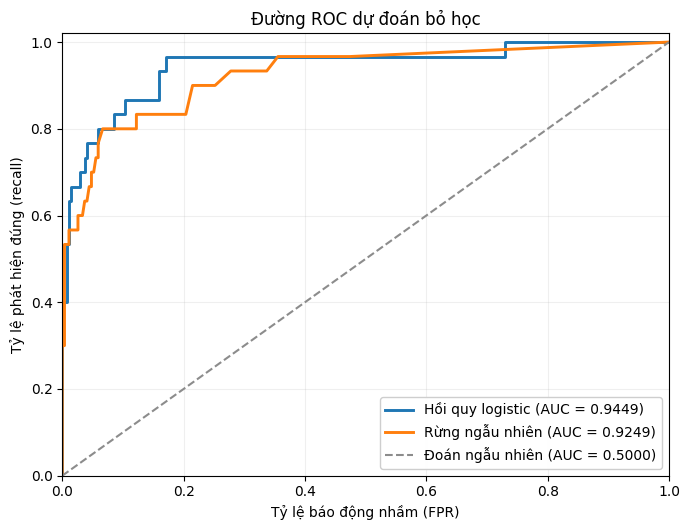

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

du_lieu = pd.read_csv("data/sinh_vien_bo_hoc.csv")
dac_trung = du_lieu.drop(columns="bo_hoc")
nhan = du_lieu["bo_hoc"]
X_hoc, X_kiem_tra, y_hoc, y_kiem_tra = train_test_split(
    dac_trung, nhan, test_size=0.25, random_state=17, stratify=nhan
)

cac_mo_hinh = {
    "Hồi quy logistic": make_pipeline(StandardScaler(), LogisticRegression()),
    "Rừng ngẫu nhiên": RandomForestClassifier(200, random_state=0),
}
duong_roc = {}
plt.figure(figsize=(7.0, 5.4))
for ten, mo_hinh in cac_mo_hinh.items():
    xac_suat = mo_hinh.fit(X_hoc, y_hoc).predict_proba(X_kiem_tra)[:, 1]
    fpr, tpr, _ = roc_curve(y_kiem_tra, xac_suat)
    auc = roc_auc_score(y_kiem_tra, xac_suat)
    duong_roc[ten] = (fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2.1, label=f"{ten} (AUC = {auc:.4f})")
    print(f"{ten}: AUC = {auc:.4f}")

# So sánh trên các đoạn đã vẽ, tại các FPR không trùng đỉnh của đường ROC.
print("\nRecall nội suy trên đường vẽ tại một vài mức FPR")
for muc_fpr in (0.015, 0.075, 0.175, 0.55, 0.75):
    cac_recall = {ten: np.interp(muc_fpr, fpr, tpr) for ten, (fpr, tpr) in duong_roc.items()}
    print(f"FPR = {muc_fpr:.1%}: " + ", ".join(
        f"{ten} {diem:.4f}" for ten, diem in cac_recall.items()
    ))

plt.plot([0, 1], [0, 1], "--", color="0.55", label="Đoán ngẫu nhiên (AUC = 0.5000)")
plt.title("Đường ROC dự đoán bỏ học")
plt.xlabel("Tỷ lệ báo động nhầm (FPR)")
plt.ylabel("Tỷ lệ phát hiện đúng (recall)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.2)
plt.legend(loc="lower right", framealpha=0.95)
plt.tight_layout()

thu_muc_hinh = Path("figures")
thu_muc_hinh.mkdir(exist_ok=True)
tep_hinh = thu_muc_hinh / "roc.png"
plt.savefig(tep_hinh, dpi=180, bbox_inches="tight")
print(f"\nĐã lưu {tep_hinh.as_posix()}")
plt.show()

**Giải thích và nhận xét**

Logistic ôm sát góc trên trái hơn xét tổng thể, với AUC `0.9449` so với `0.9249` của rừng ngẫu nhiên. Hai đường có đoạn trùng nhau (ví dụ tại FPR `7.5%`) và có giao nhau. Trên đường vẽ, logistic cao hơn tại FPR `17.5%`, rừng cao hơn tại `55%`, rồi logistic trở lại cao hơn tại `75%`. Sự đổi thứ tự cho thấy AUC lớn hơn vẫn có thể đi kèm recall thấp hơn ở một số mức FPR.

## Bài 5. Cân bằng lớp cho mô hình khác

**Đề bài**

So sánh precision, recall và F1 của `RandomForestClassifier` và `SVC` trên tập kiểm tra trước và sau khi đặt `class_weight="balanced"`. Giải thích mô hình nào thay đổi nhiều nhất.

In [5]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

du_lieu = pd.read_csv("data/sinh_vien_bo_hoc.csv")
dac_trung = du_lieu.drop(columns="bo_hoc")
nhan = du_lieu["bo_hoc"]
X_hoc, X_kiem_tra, y_hoc, y_kiem_tra = train_test_split(
    dac_trung, nhan, test_size=0.25, random_state=17, stratify=nhan
)

ten_thuoc_do = ["Precision", "Recall", "F1"]
ket_qua = []
for trang_thai, trong_so in [("Mặc định", None), ("Cân bằng", "balanced")]:
    cac_mo_hinh = {
        "Rừng ngẫu nhiên": RandomForestClassifier(200, random_state=0, class_weight=trong_so),
        "SVM RBF": make_pipeline(
            StandardScaler(),
            SVC(probability=True, random_state=0, class_weight=trong_so),
        ),
    }
    for ten, mo_hinh in cac_mo_hinh.items():
        xac_suat = mo_hinh.fit(X_hoc, y_hoc).predict_proba(X_kiem_tra)[:, 1]
        du_doan = (xac_suat >= 0.5).astype(int)
        ket_qua.append({
            "Mô hình": ten,
            "Trọng số": trang_thai,
            "Precision": precision_score(y_kiem_tra, du_doan, zero_division=0),
            "Recall": recall_score(y_kiem_tra, du_doan, zero_division=0),
            "F1": f1_score(y_kiem_tra, du_doan, zero_division=0),
            "Số cảnh báo": int(du_doan.sum()),
        })

bang = pd.DataFrame(ket_qua).set_index(["Mô hình", "Trọng số"])
chenh_lech = bang.xs("Cân bằng", level="Trọng số")[ten_thuoc_do] - bang.xs(
    "Mặc định", level="Trọng số"
)[ten_thuoc_do]
chenh_lech["Tổng |chênh lệch|"] = chenh_lech.abs().sum(axis=1)
print("Cùng tập kiểm tra, báo bỏ học khi xác suất ≥ 0.5")
print(bang.to_string(float_format=lambda diem: f"{diem:.4f}"))
print("\nChênh lệch do cân bằng lớp")
print(chenh_lech.to_string(float_format=lambda diem: f"{diem:+.4f}"))
print(f"\nThay đổi nhiều nhất theo tổng độ lệch: {chenh_lech['Tổng |chênh lệch|'].idxmax()}")

Cùng tập kiểm tra, báo bỏ học khi xác suất ≥ 0.5
                          Precision  Recall     F1  Số cảnh báo
Mô hình         Trọng số                                       
Rừng ngẫu nhiên Mặc định     0.7727  0.5667 0.6538           22
SVM RBF         Mặc định     0.8333  0.5000 0.6250           18
Rừng ngẫu nhiên Cân bằng     0.5250  0.7000 0.6000           40
SVM RBF         Cân bằng     0.8125  0.4333 0.5652           16

Chênh lệch do cân bằng lớp
                 Precision  Recall      F1  Tổng |chênh lệch|
Mô hình                                                      
Rừng ngẫu nhiên    -0.2477 +0.1333 -0.0538            +0.4349
SVM RBF            -0.0208 -0.0667 -0.0598            +0.1473

Thay đổi nhiều nhất theo tổng độ lệch: Rừng ngẫu nhiên


C:\Users\Huỳnh Phúc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Huỳnh Phúc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


**Giải thích và nhận xét**

Giữ ngưỡng xác suất `0.5` và cách chia của mục 6 cho cả hai mô hình. **Rừng ngẫu nhiên thay đổi nhiều nhất** theo tổng độ lệch tuyệt đối của precision, recall và F1 (`0.4349` so với `0.1473`). Rừng tăng số cảnh báo từ 22 lên 40, giúp recall từ `0.5667` lên `0.7000`, đồng thời giảm precision từ `0.7727` xuống `0.5250`. Ở SVM RBF, số cảnh báo giảm từ 18 xuống 16 và recall giảm từ `0.5000` xuống `0.4333` tại cùng ngưỡng. Cân bằng lớp thay đổi quá trình fit, nên recall tại một ngưỡng xác suất cố định có thể tăng hoặc giảm. F1 ở đây giảm với cả hai mô hình.

## Bài 6. MAE và RMSE với một lần đoán hỏng

**Đề bài**

Tính MAE, RMSE và $R^2$ của hồi quy tuyến tính trên tập kiểm tra dữ liệu giá nhà Lab 1. Cộng 5 tỷ vào dự đoán của đúng một căn rồi tính lại các chỉ số. So sánh mức thay đổi và giải thích cách RMSE phạt sai số lớn.

In [6]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

du_lieu_nha = pd.read_csv("data/gia_nha.csv")
# Giữ biến đầu vào và cách chia của bước đánh giá mô hình ở Lab 1.
X_hoc, X_kiem_tra, gia_hoc, gia_kiem_tra = train_test_split(
    du_lieu_nha[["dien_tich"]], du_lieu_nha["gia"],
    test_size=0.2, random_state=42,
)
mo_hinh_nha = LinearRegression().fit(X_hoc, gia_hoc)
du_doan_goc = mo_hinh_nha.predict(X_kiem_tra)

vi_tri_can_nha = 0
du_doan_hong = du_doan_goc.copy()
du_doan_hong[vi_tri_can_nha] += 5.0
gia_that = gia_kiem_tra.iloc[vi_tri_can_nha]

print(f"Tập học: {len(X_hoc)} căn. Tập kiểm tra: {len(X_kiem_tra)} căn.")
print(f"Căn được chọn: dòng chỉ số {gia_kiem_tra.index[vi_tri_can_nha]} "
      f"(tính từ 0), diện tích {X_kiem_tra.iloc[vi_tri_can_nha]['dien_tich']:.1f} m².")
print(f"Giá thật {gia_that:.4f} tỷ, dự đoán gốc {du_doan_goc[vi_tri_can_nha]:.4f} tỷ, "
      f"sau khi cộng {du_doan_hong[vi_tri_can_nha]:.4f} tỷ.")
print(f"Số dự đoán bị thay đổi: {np.count_nonzero(du_doan_hong != du_doan_goc)}")


def do_sai_so(gia_that, gia_du_doan):
    return {
        "MAE (tỷ đồng)": mean_absolute_error(gia_that, gia_du_doan),
        "RMSE (tỷ đồng)": np.sqrt(mean_squared_error(gia_that, gia_du_doan)),
        "R²": r2_score(gia_that, gia_du_doan),
    }


bang = pd.DataFrame({
    "Ban đầu": do_sai_so(gia_kiem_tra, du_doan_goc),
    "Sau khi cộng 5 tỷ": do_sai_so(gia_kiem_tra, du_doan_hong),
})
bang["Chênh lệch"] = bang["Sau khi cộng 5 tỷ"] - bang["Ban đầu"]
print(bang.to_string(float_format=lambda diem: f"{diem:.4f}"))
for ten in ("MAE (tỷ đồng)", "RMSE (tỷ đồng)"):
    ty_le = bang.loc[ten, "Chênh lệch"] / bang.loc[ten, "Ban đầu"]
    print(f"{ten} tăng {ty_le:.1%}.")

Tập học: 48 căn. Tập kiểm tra: 12 căn.
Căn được chọn: dòng chỉ số 0 (tính từ 0), diện tích 35.5 m².
Giá thật 3.0000 tỷ, dự đoán gốc 3.2179 tỷ, sau khi cộng 8.2179 tỷ.
Số dự đoán bị thay đổi: 1
                Ban đầu  Sau khi cộng 5 tỷ  Chênh lệch
MAE (tỷ đồng)    0.2578             0.6745      0.4167
RMSE (tỷ đồng)   0.3730             1.5505      1.1775
R²               0.9622             0.3475     -0.6148
MAE (tỷ đồng) tăng 161.6%.
RMSE (tỷ đồng) tăng 315.6%.


**Giải thích và nhận xét**

Mô hình dùng `dien_tich` và chia 80/20 với `random_state=42`, như bước đánh giá của Lab 1. Căn đầu tiên theo thứ tự tập kiểm tra có diện tích 35,5 m², giá thật 3 tỷ. Dự đoán tăng từ 3,2179 lên 8,2179 tỷ. Các giá trị đo sau khi sửa thuộc cùng mô hình và cùng tập kiểm tra.

**RMSE thay đổi nhiều nhất trong hai thước đo có đơn vị tỷ đồng.** MAE tăng từ `0.2578` lên `0.6745` (tăng 0,4167 tỷ, khoảng 161,6%). RMSE tăng từ `0.3730` lên `1.5505` (tăng 1,1775 tỷ, khoảng 315,6%). Sai số tuyệt đối của căn được chọn tăng đúng 5 tỷ, nên MAE tăng $5/12$. RMSE bình phương sai số từng căn trước khi lấy trung bình và căn bậc hai, vì vậy sai số 5,2179 tỷ làm tổng bình phương tăng mạnh.

$R^2$ giảm từ `0.9622` xuống `0.3475` vì tổng bình phương phần dư tăng trong khi độ biến thiên của giá thật giữ nguyên. $R^2$ là chỉ số không có đơn vị.